# Composed hazard and bands

At each checkpoint the action probabilities mix expected drive and pass failure risk. Half-life bands map the hazard to an interpretable four-level scale. **own derivation; design choice**

## Model and inputs

Let q=P(pass|s), r_d=drive risk, and r_p=Σ_k p(destination k|pass,s)[1−p(success|k,s)]. Then h=(1−q)r_d+q r_p. Because destination probabilities sum to one, r_p=1−Σ_k p_k p(success|k). **own derivation**. Band cutoffs use h=1−2^(−1/n), for n=1,2,4,8. The operational labels are None, Low, Medium, High; the fifth h>0.5 band is intentionally not used. **design choice**.

## Usage and visual

The following code uses deterministic synthetic inputs. Any printed quantities and figure values are computed by this cell; no match-level data are embedded.

## Component scope and model limits

Composition is the repository’s own model definition; discrete-time hazard context [@singer2003].

The composed quantity is the raw next-action hazard from the stored branch components. It is conditional on component definitions and outputs; the vignette does not add a post-hoc calibrator. The band names discretize this hazard for interpretation. **model scope; design choice**


Computed half-life cutoffs: [0.5        0.29289322 0.15910358 0.08299596]


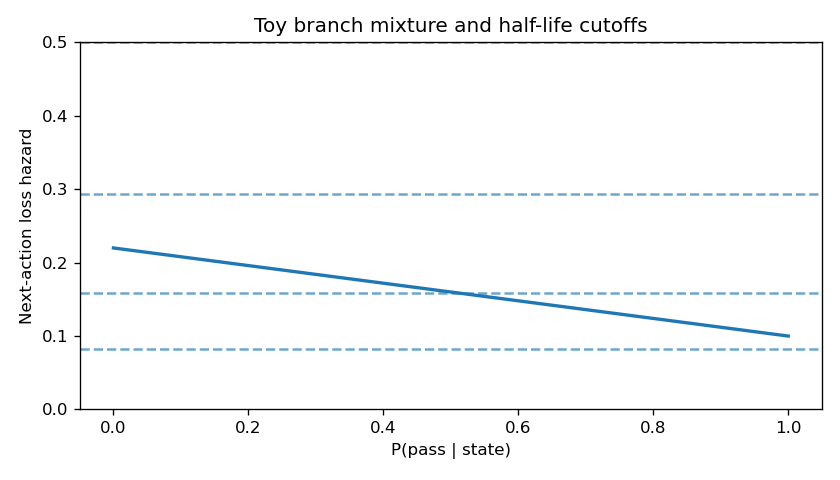

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
n=np.array([1,2,4,8]); cuts=1-2.0**(-1/n);
p_pass=np.linspace(0,1,101); drive_risk=0.22; pass_failure=0.10; h=(1-p_pass)*drive_risk+p_pass*pass_failure
fig,ax=plt.subplots(figsize=(7,4)); ax.plot(p_pass,h,lw=2);
for c in cuts: ax.axhline(c,ls="--",alpha=.65)
ax.set(xlabel="P(pass | state)",ylabel="Next-action loss hazard",ylim=(0,.5),title="Toy branch mixture and half-life cutoffs"); fig.tight_layout()
out=Path("figures/vignette_05_hazard_bands.png"); out.parent.mkdir(exist_ok=True); fig.savefig(out,dpi=150); fig.savefig(out.with_suffix(".svg"))
print("Computed half-life cutoffs:", cuts)